In [53]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,roc_curve,
    precision_recall_curve,average_precision_score
)
# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier


| العمود                | معناه                                         | نوع البيانات | مثال                                    |
| --------------------- | --------------------------------------------- | ------------ | --------------------------------------- |
| **id**                | رقم مميز لكل شخص                              | رقمي         | `9046`                                  |
| **gender**            | نوع الشخص                                     | Categorical  | Male / Female                           |
| **age**               | عمر الشخص بالسنوات                            | Numerical    | `67`                                    |
| **hypertension**      | هل عنده ضغط دم مرتفع؟                         | Binary       | `0` = لا، `1` = نعم                     |
| **heart_disease**     | هل عنده مرض بالقلب؟                           | Binary       | `0` = لا، `1` = نعم                     |
| **ever_married**      | هل الشخص اتجوز قبل كده؟                       | Binary       | `0` = لا، `1` = نعم                     |
| **work_type**         | نوع العمل                                     | Categorical  | Private / Self-employed                 |
| **Residence_type**    | مكان السكن                                    | Categorical  | Urban / Rural                           |
| **avg_glucose_level** | متوسط مستوى الجلوكوز في الدم                  | Numerical    | `228.69`                                |
| **bmi**               | مؤشر كتلة الجسم                               | Numerical    | `36.6`                                  |
| **smoking_status**    | حالة التدخين                                  | Categorical  | formerly smoked / never smoked / smokes |
| **stroke**            | هل حصلت للشخص سكتة دماغية؟ **وده الـ Target** | Binary       | `0` = لا، `1` = نعم                     |


In [54]:
df = pd.read_csv('healthcare-dataset-stroke-data.csv')
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [55]:
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [56]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB


In [57]:
df.isnull().sum()

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

In [58]:
df.dropna()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
5,56669,Male,81.0,0,0,Yes,Private,Urban,186.21,29.0,formerly smoked,1
...,...,...,...,...,...,...,...,...,...,...,...,...
5104,14180,Female,13.0,0,0,No,children,Rural,103.08,18.6,Unknown,0
5106,44873,Female,81.0,0,0,Yes,Self-employed,Urban,125.20,40.0,never smoked,0
5107,19723,Female,35.0,0,0,Yes,Self-employed,Rural,82.99,30.6,never smoked,0
5108,37544,Male,51.0,0,0,Yes,Private,Rural,166.29,25.6,formerly smoked,0


In [59]:
df.dropna(inplace=True)

In [60]:
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
5,56669,Male,81.0,0,0,Yes,Private,Urban,186.21,29.0,formerly smoked,1


In [61]:
df.shape

(4909, 12)

In [62]:
df.reset_index(drop=True,inplace=True)

In [63]:
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
2,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
3,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
4,56669,Male,81.0,0,0,Yes,Private,Urban,186.21,29.0,formerly smoked,1


In [64]:
df.duplicated().sum()

np.int64(0)

In [65]:
df.drop('id',axis=1,inplace=True)


In [66]:
df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
2,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
3,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
4,Male,81.0,0,0,Yes,Private,Urban,186.21,29.0,formerly smoked,1


In [67]:
df.isnull().sum()

gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64

<Axes: xlabel='avg_glucose_level', ylabel='Count'>

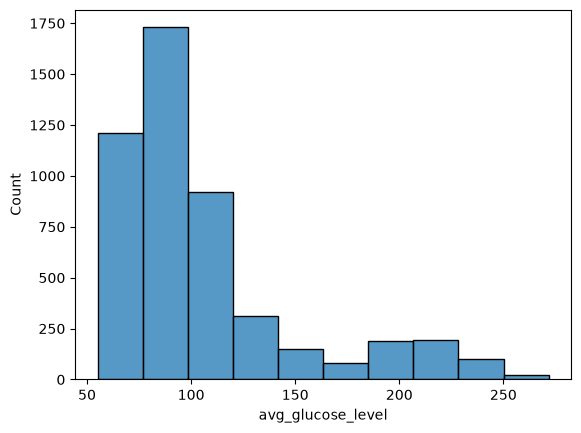

In [68]:
sns.histplot(data=df,x='avg_glucose_level',bins=10)

<Axes: xlabel='smoking_status', ylabel='count'>

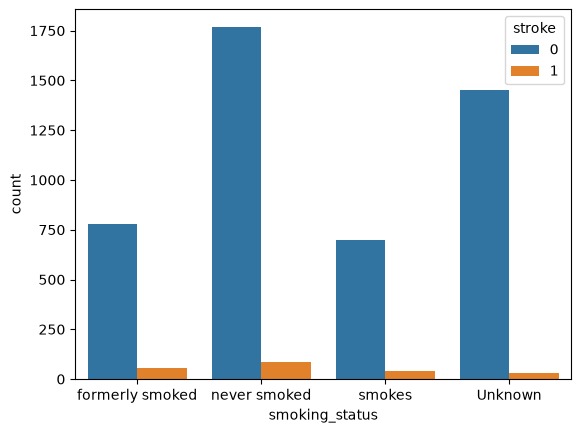

In [69]:

sns.countplot(data=df,x='smoking_status',hue='stroke')

<Axes: xlabel='bmi', ylabel='Count'>

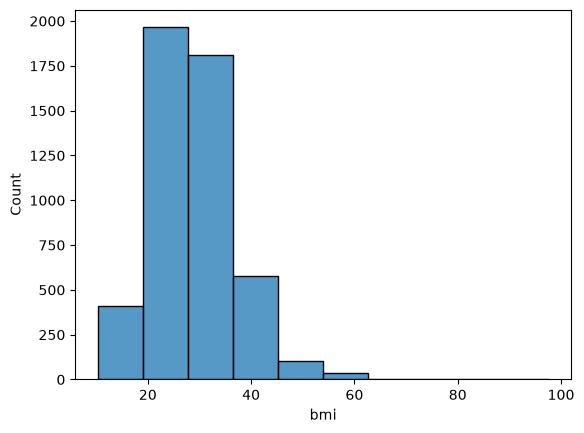

In [70]:
sns.histplot(data=df,x='bmi',bins=10)

<Axes: xlabel='Residence_type', ylabel='count'>

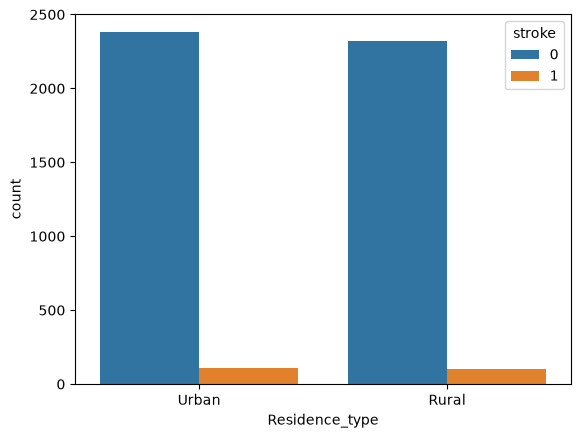

In [71]:
sns.countplot(data=df,x='Residence_type',hue='stroke')

<Axes: xlabel='gender', ylabel='count'>

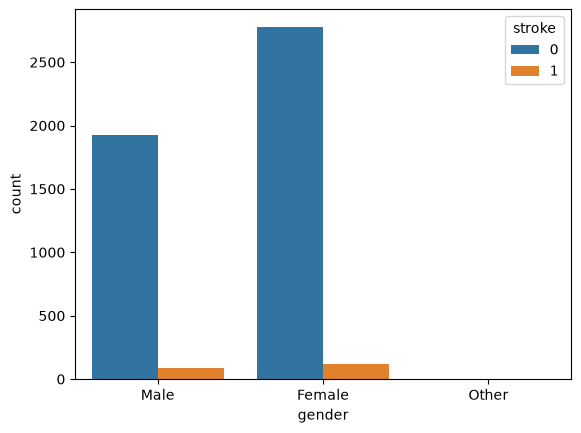

In [72]:
sns.countplot(data=df,x='gender',hue='stroke')

<Axes: xlabel='age', ylabel='Count'>

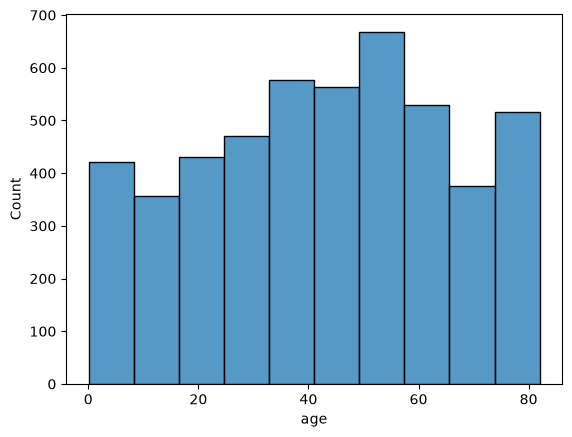

In [73]:
sns.histplot(data=df,x='age',bins=10)

<Axes: xlabel='hypertension', ylabel='count'>

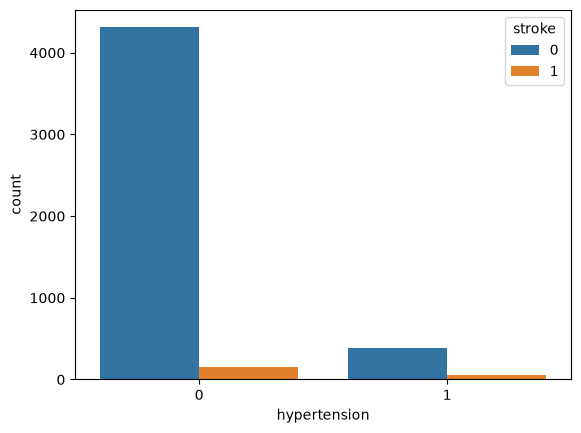

In [74]:
sns.countplot(data=df,x='hypertension',hue='stroke')

<Axes: xlabel='heart_disease', ylabel='count'>

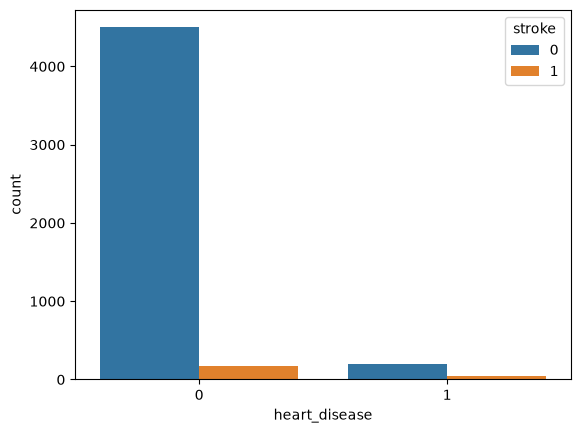

In [75]:
sns.countplot(data=df,x='heart_disease',hue='stroke')

<Axes: xlabel='ever_married', ylabel='count'>

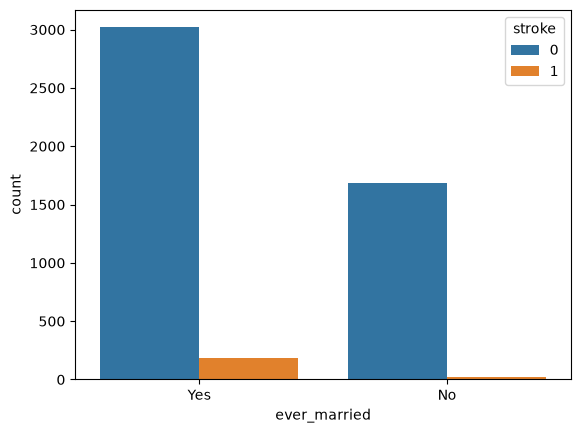

In [76]:
 
sns.countplot(data=df,x='ever_married',hue='stroke')

<Axes: xlabel='work_type', ylabel='count'>

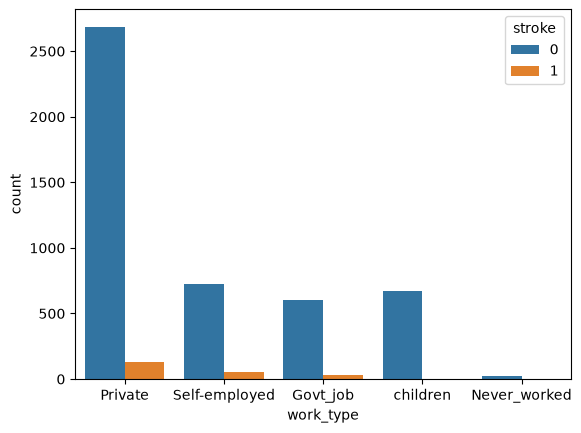

In [77]:

sns.countplot(data=df,x='work_type',hue='stroke')

<Axes: xlabel='stroke', ylabel='count'>

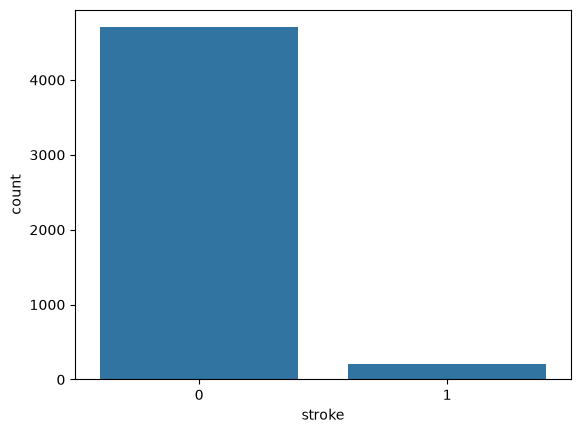

In [78]:
sns.countplot(data=df,x='stroke')

In [79]:
df['stroke'].value_counts()

stroke
0    4700
1     209
Name: count, dtype: int64

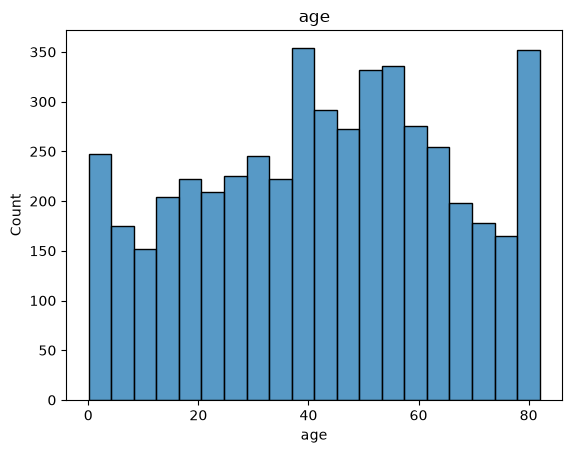

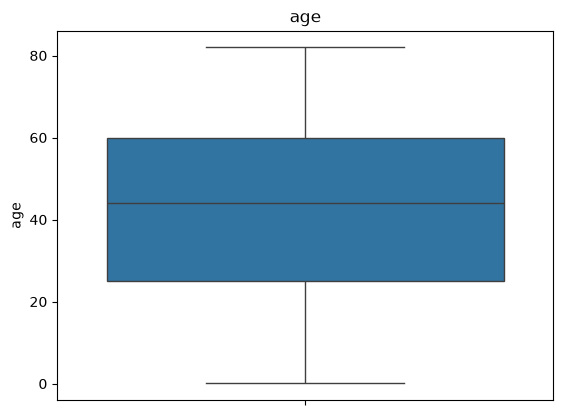

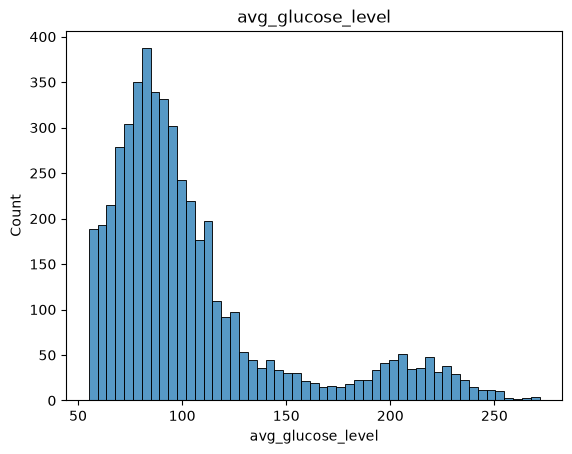

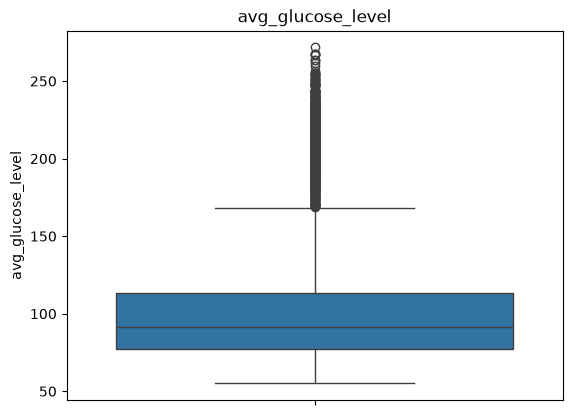

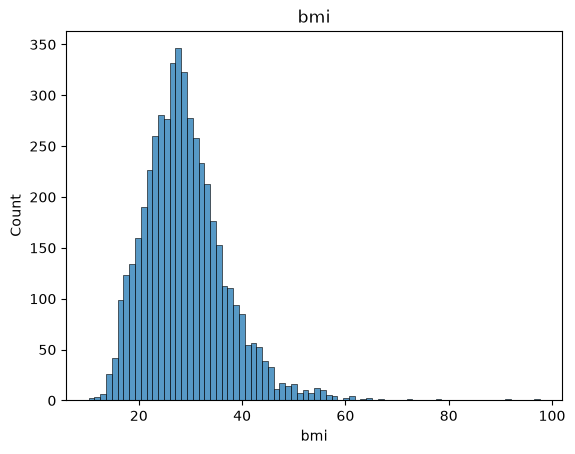

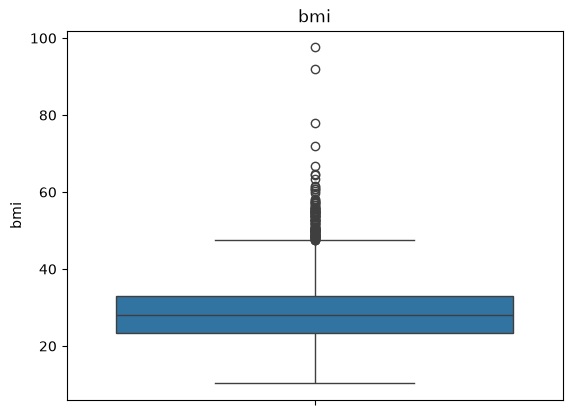

In [80]:
#numeric_cols=df.select_dtypes(include='number').columns
numeric_cols =['age','avg_glucose_level','bmi']
for col in numeric_cols:
    plt.Figure(figsize=(5,5))
    sns.histplot(df[col])
    plt.title(col)
    plt.show()

    plt.Figure(figsize=(5,5))
    sns.boxplot(df[col])
    plt.title(col)
    plt.show()


In [81]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df['gender']=le.fit_transform(df['gender'])
df['Residence_type']=le.fit_transform(df['Residence_type'])
df['ever_married']=le.fit_transform(df['ever_married'])

In [82]:
from sklearn.preprocessing import OneHotEncoder
ohe = OneHotEncoder()

onhot=OneHotEncoder(sparse_output=False,drop='first',handle_unknown='ignore').set_output(transform='pandas')

In [83]:
temp1=onhot.fit_transform(df[['smoking_status']])
temp2=onhot.fit_transform(df[['work_type']])

In [84]:
df=pd.concat([df,temp1],axis=1)
df=pd.concat([df,temp2],axis=1)

In [85]:
df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children
0,1,67.0,0,1,1,Private,1,228.69,36.6,formerly smoked,1,1.0,0.0,0.0,0.0,1.0,0.0,0.0
1,1,80.0,0,1,1,Private,0,105.92,32.5,never smoked,1,0.0,1.0,0.0,0.0,1.0,0.0,0.0
2,0,49.0,0,0,1,Private,1,171.23,34.4,smokes,1,0.0,0.0,1.0,0.0,1.0,0.0,0.0
3,0,79.0,1,0,1,Self-employed,0,174.12,24.0,never smoked,1,0.0,1.0,0.0,0.0,0.0,1.0,0.0
4,1,81.0,0,0,1,Private,1,186.21,29.0,formerly smoked,1,1.0,0.0,0.0,0.0,1.0,0.0,0.0


In [86]:
df.drop(['work_type','smoking_status'],axis=1,inplace = True)

In [87]:
df.head()

,gender,age,hypertension,heart_disease,ever_married,Residence_type,avg_glucose_level,bmi,stroke,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children
0,1,67.0,0,1,1,1,228.69,36.6,1,1.0,0.0,0.0,0.0,1.0,0.0,0.0
1,1,80.0,0,1,1,0,105.92,32.5,1,0.0,1.0,0.0,0.0,1.0,0.0,0.0
2,0,49.0,0,0,1,1,171.23,34.4,1,0.0,0.0,1.0,0.0,1.0,0.0,0.0
3,0,79.0,1,0,1,0,174.12,24.0,1,0.0,1.0,0.0,0.0,0.0,1.0,0.0
4,1,81.0,0,0,1,1,186.21,29.0,1,1.0,0.0,0.0,0.0,1.0,0.0,0.0


In [89]:
df.head()

,gender,age,hypertension,heart_disease,ever_married,Residence_type,avg_glucose_level,bmi,stroke,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children
0,1,1.070138,0,1,1,1,2.777698,0.981345,1,1.0,0.0,0.0,0.0,1.0,0.0,0.0
1,1,1.646563,0,1,1,0,0.013842,0.459269,1,0.0,1.0,0.0,0.0,1.0,0.0,0.0
2,0,0.272012,0,0,1,1,1.484132,0.701207,1,0.0,0.0,1.0,0.0,1.0,0.0,0.0
3,0,1.602222,1,0,1,0,1.549193,-0.623083,1,0.0,1.0,0.0,0.0,0.0,1.0,0.0
4,1,1.690903,0,0,1,1,1.821368,0.013595,1,1.0,0.0,0.0,0.0,1.0,0.0,0.0


In [ ]:
x=df.drop(columns='stroke')
y=df['stroke']
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [100]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(x_train)
X_test_scaled = scaler.transform(x_test)

In [91]:
df = df.loc[:, ~df.columns.duplicated()]

In [101]:
models = {

    # Linear
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=1),

    # Distance-based
    "KNN": KNeighborsClassifier(n_neighbors=5),

    # SVM
    "SVC": SVC(probability=True, random_state=1),

    # Tree
    "Decision Tree": DecisionTreeClassifier(random_state=1),

    # Naive Bayes
    "Naive Bayes": GaussianNB(),

    # Bagging Based
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=1),

    # Boosting
    "AdaBoost": AdaBoostClassifier(random_state=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=1),

    # External Boosting Libraries
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=1, use_label_encoder=False),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=1),
    "LightGBM": LGBMClassifier(random_state=1)
}

  0%|          | 0/13 [00:00<?, ?it/s]


Confusion Matrix:
 [[929   0]
 [ 53   0]]


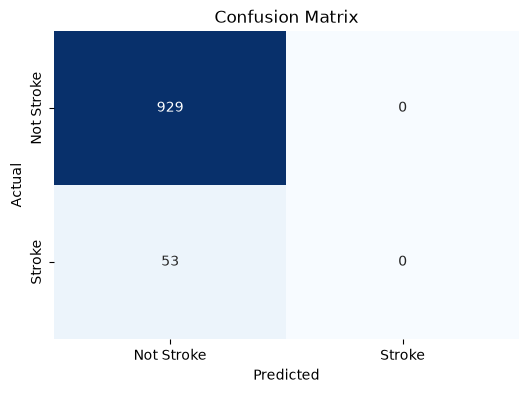


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97       929
      Stroke       0.00      0.00      0.00        53

    accuracy                           0.95       982
   macro avg       0.47      0.50      0.49       982
weighted avg       0.89      0.95      0.92       982

ROC-AUC: 0.853910676929951


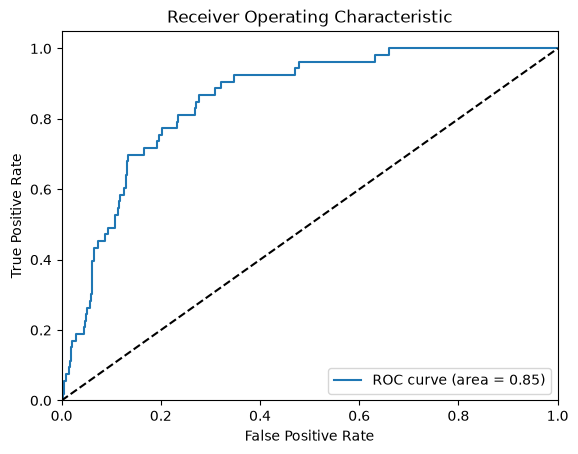

PR AUC: 0.22091264061416985


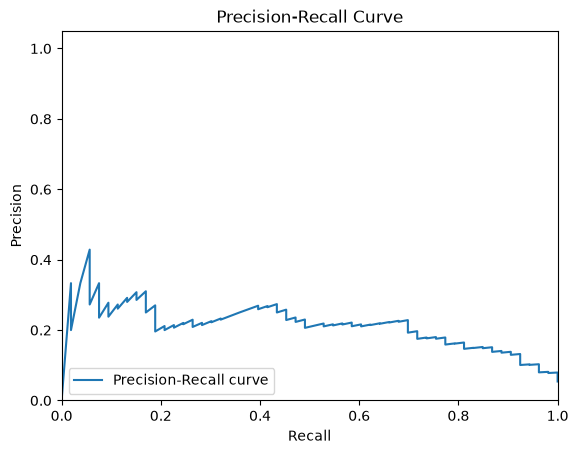

c:\Users\PC\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
  8%|▊         | 1/13 [00:00<00:03,  3.67it/s]


Confusion Matrix:
 [[928   1]
 [ 53   0]]


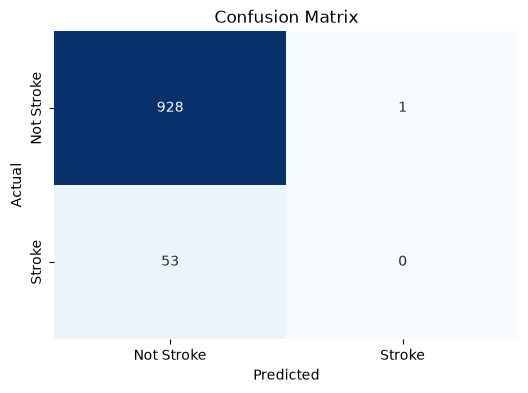


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97       929
      Stroke       0.00      0.00      0.00        53

    accuracy                           0.95       982
   macro avg       0.47      0.50      0.49       982
weighted avg       0.89      0.95      0.92       982

ROC-AUC: 0.6258504782988403


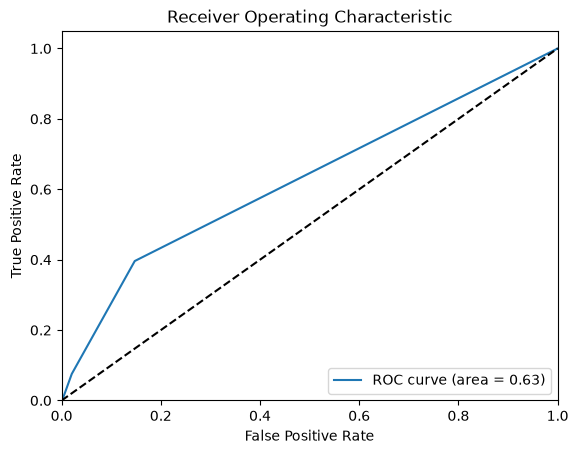

PR AUC: 0.08834402681460123


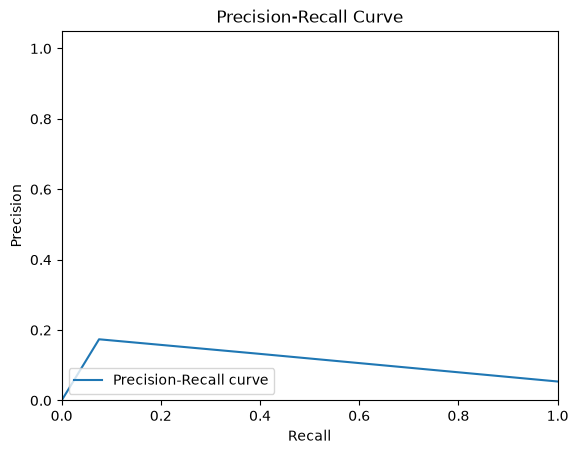

 15%|█▌        | 2/13 [00:00<00:03,  3.18it/s]c:\Users\PC\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(



Confusion Matrix:
 [[929   0]
 [ 53   0]]


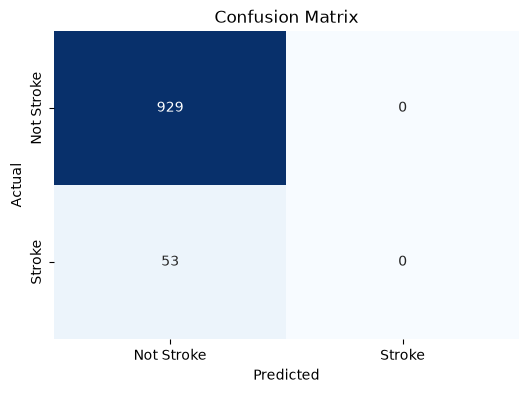


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97       929
      Stroke       0.00      0.00      0.00        53

    accuracy                           0.95       982
   macro avg       0.47      0.50      0.49       982
weighted avg       0.89      0.95      0.92       982

ROC-AUC: 0.6671202550927149


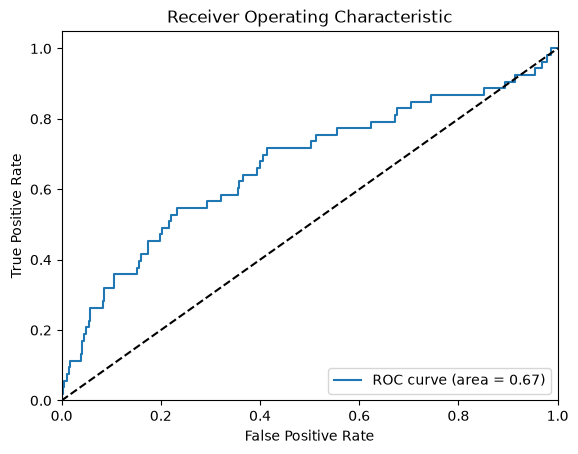

PR AUC: 0.139483460002192


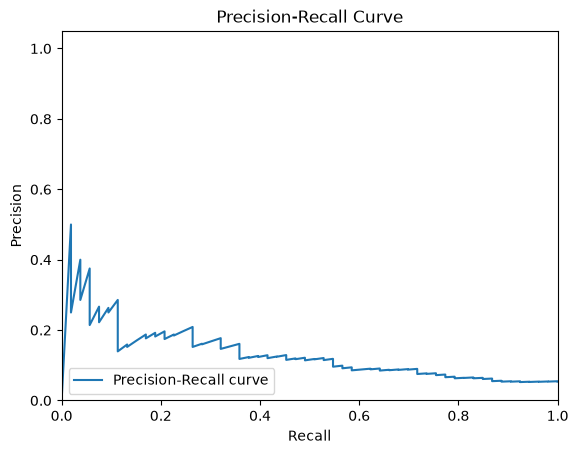

c:\Users\PC\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\PC\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
 23%|██▎       | 3/13 [00:01<00:06,  1.55it/s]


Confusion Matrix:
 [[899  30]
 [ 45   8]]


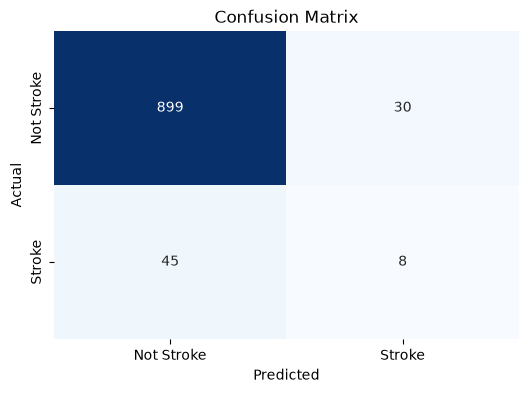


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      0.97      0.96       929
      Stroke       0.21      0.15      0.18        53

    accuracy                           0.92       982
   macro avg       0.58      0.56      0.57       982
weighted avg       0.91      0.92      0.92       982

ROC-AUC: 0.5593253041411946


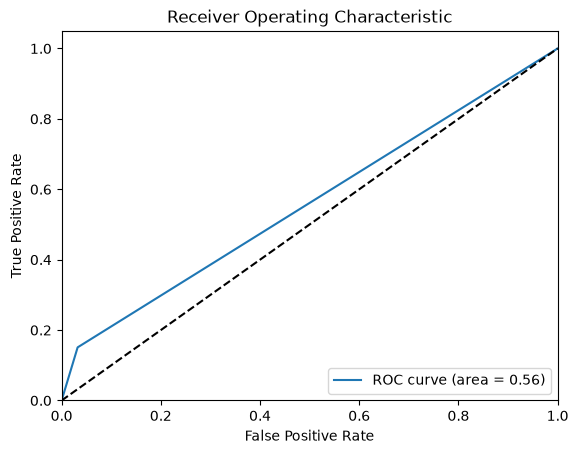

PR AUC: 0.07760240435080709


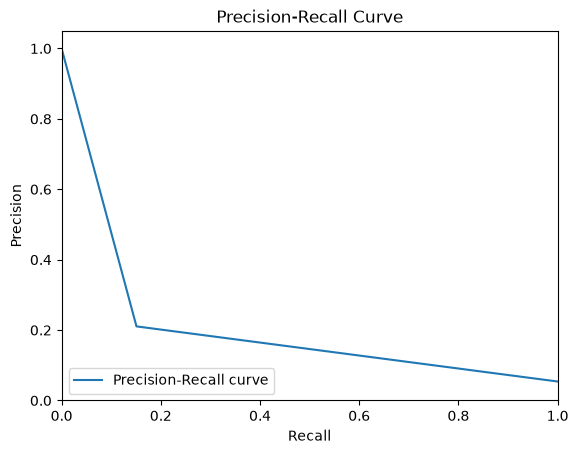

 31%|███       | 4/13 [00:02<00:04,  1.90it/s]


Confusion Matrix:
 [[322 607]
 [  0  53]]


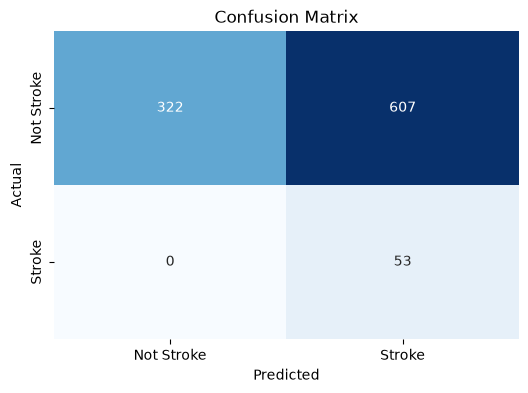


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      0.35      0.51       929
      Stroke       0.08      1.00      0.15        53

    accuracy                           0.38       982
   macro avg       0.54      0.67      0.33       982
weighted avg       0.95      0.38      0.50       982

ROC-AUC: 0.8227958648983488


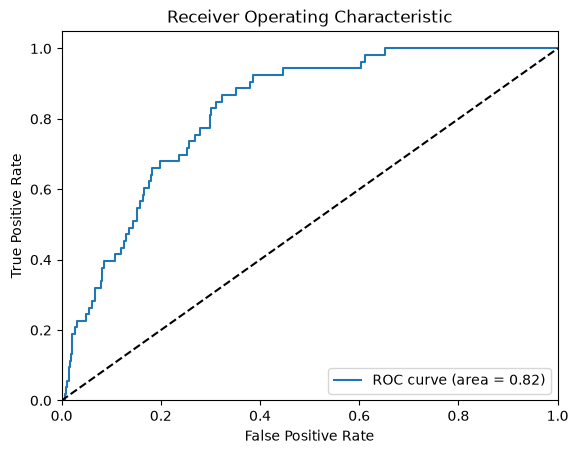

PR AUC: 0.1825440610613316


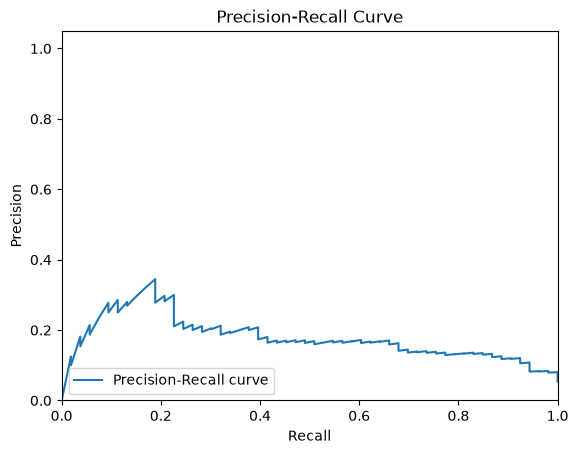

 38%|███▊      | 5/13 [00:02<00:03,  2.26it/s]


Confusion Matrix:
 [[929   0]
 [ 53   0]]


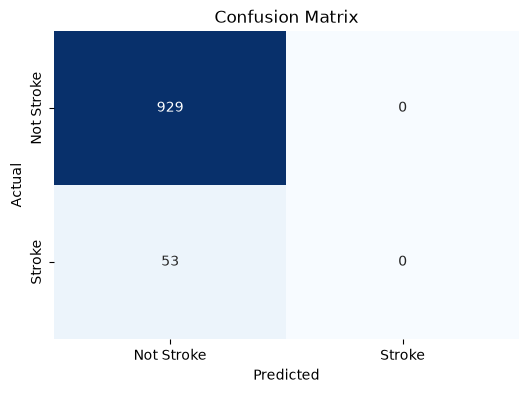


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97       929
      Stroke       0.00      0.00      0.00        53

    accuracy                           0.95       982
   macro avg       0.47      0.50      0.49       982
weighted avg       0.89      0.95      0.92       982

ROC-AUC: 0.8025265552328533


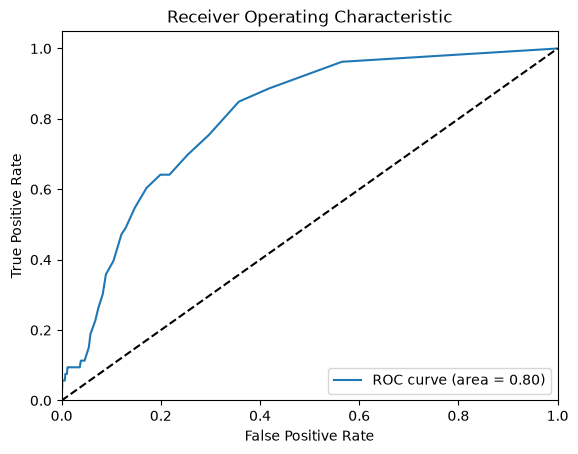

PR AUC: 0.18935213268735104


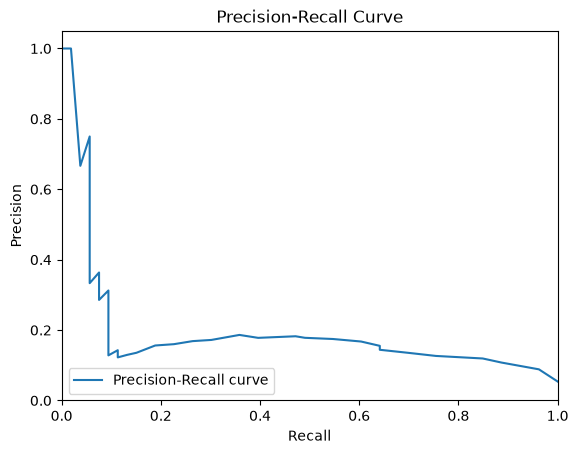

c:\Users\PC\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
 46%|████▌     | 6/13 [00:02<00:03,  2.05it/s]


Confusion Matrix:
 [[925   4]
 [ 51   2]]


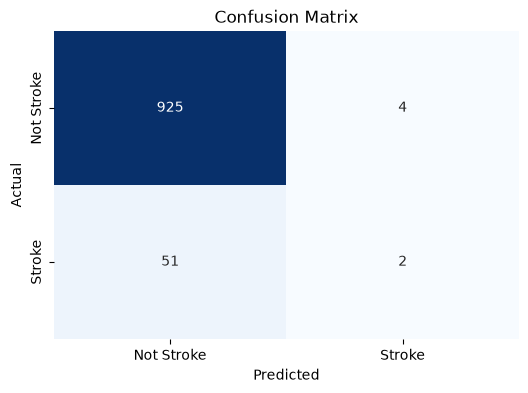


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97       929
      Stroke       0.33      0.04      0.07        53

    accuracy                           0.94       982
   macro avg       0.64      0.52      0.52       982
weighted avg       0.91      0.94      0.92       982

ROC-AUC: 0.7434246603164287


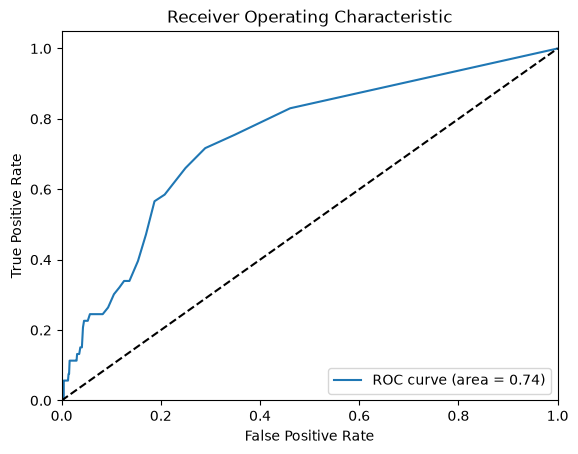

PR AUC: 0.14746637484226552


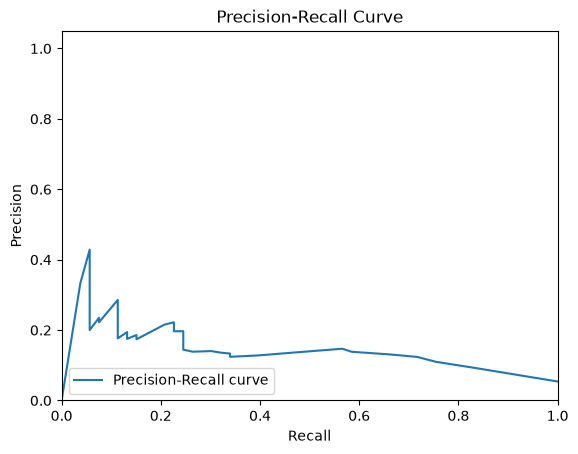

 54%|█████▍    | 7/13 [00:03<00:03,  1.93it/s]


Confusion Matrix:
 [[929   0]
 [ 53   0]]


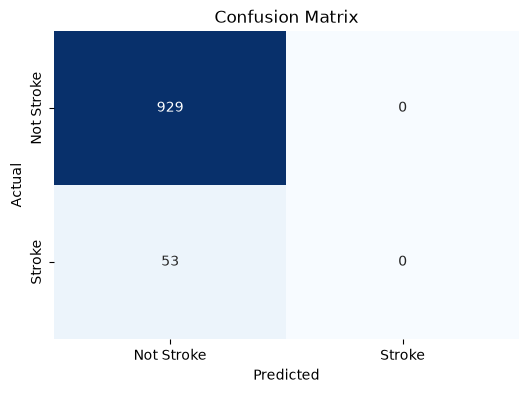


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97       929
      Stroke       0.00      0.00      0.00        53

    accuracy                           0.95       982
   macro avg       0.47      0.50      0.49       982
weighted avg       0.89      0.95      0.92       982

ROC-AUC: 0.8116355586246117


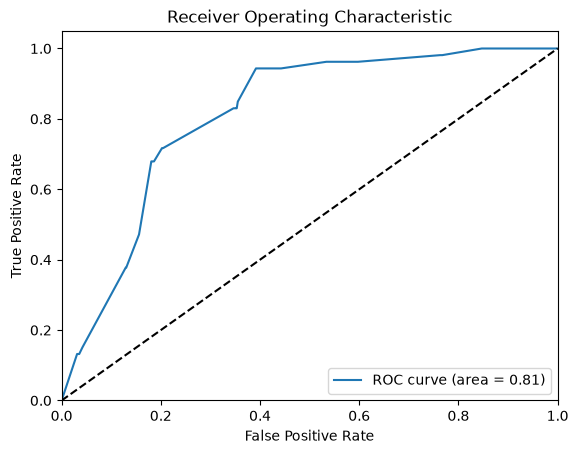

PR AUC: 0.14958871298636464


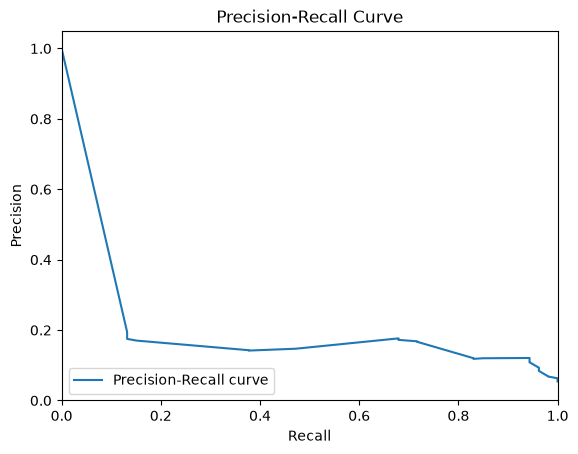

c:\Users\PC\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\PC\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
 62%|██████▏   | 8/13 [00:03<00:02,  1.99it/s]


Confusion Matrix:
 [[927   2]
 [ 53   0]]


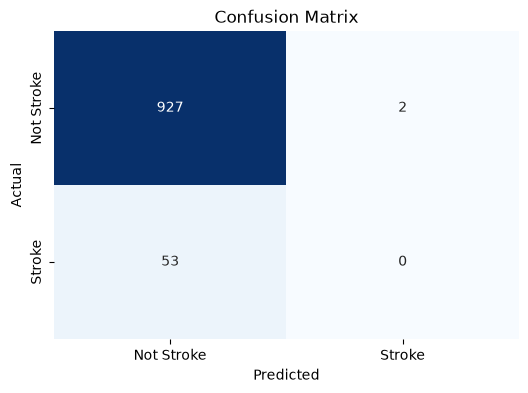


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97       929
      Stroke       0.00      0.00      0.00        53

    accuracy                           0.94       982
   macro avg       0.47      0.50      0.49       982
weighted avg       0.89      0.94      0.92       982

ROC-AUC: 0.8429636249162216


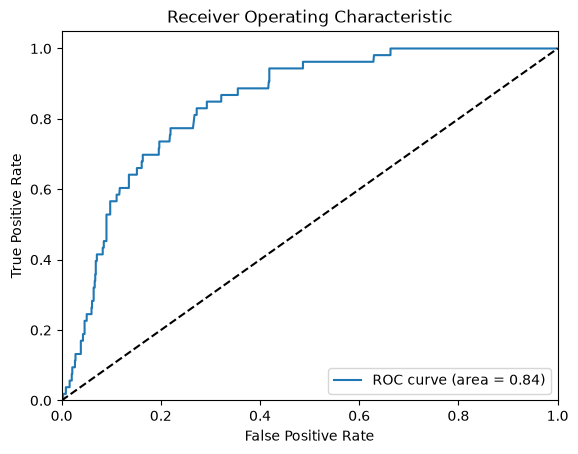

PR AUC: 0.19145860874329237


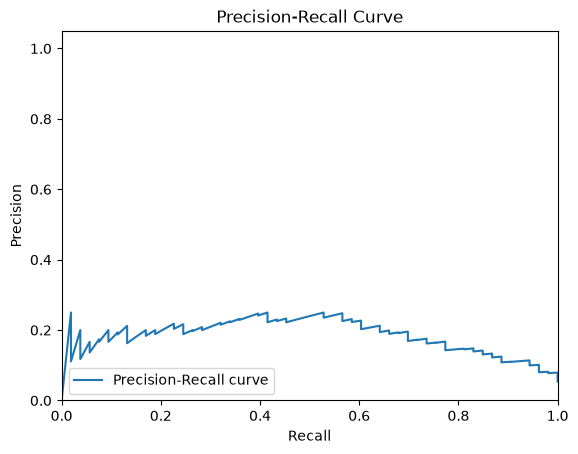

 69%|██████▉   | 9/13 [00:04<00:02,  1.73it/s]


Confusion Matrix:
 [[927   2]
 [ 52   1]]


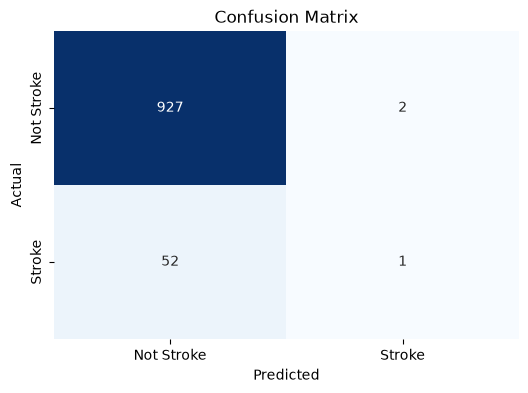


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97       929
      Stroke       0.33      0.02      0.04        53

    accuracy                           0.95       982
   macro avg       0.64      0.51      0.50       982
weighted avg       0.91      0.95      0.92       982

ROC-AUC: 0.7978755813717326


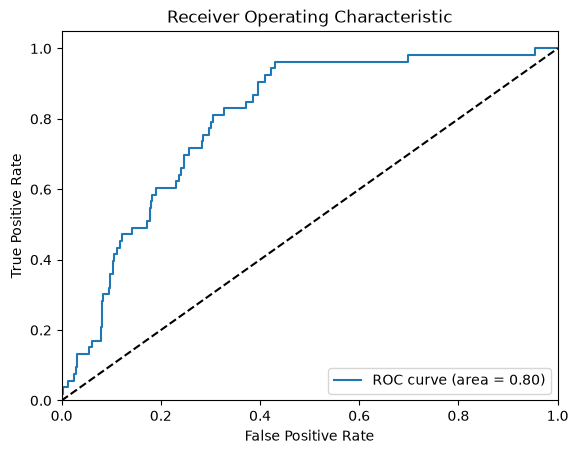

PR AUC: 0.15541396768171672


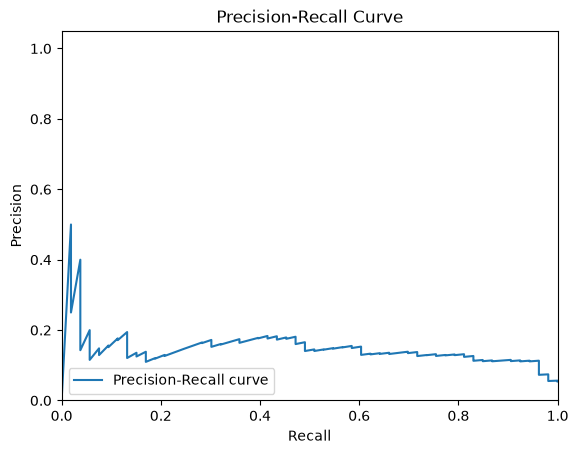

 77%|███████▋  | 10/13 [00:07<00:03,  1.33s/it]


Confusion Matrix:
 [[926   3]
 [ 50   3]]


c:\Users\PC\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [20:26:52] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


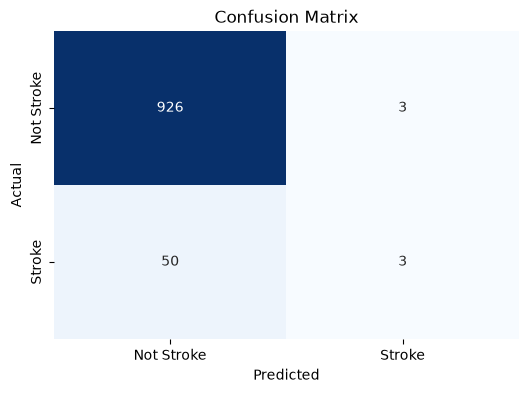


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97       929
      Stroke       0.50      0.06      0.10        53

    accuracy                           0.95       982
   macro avg       0.72      0.53      0.54       982
weighted avg       0.92      0.95      0.93       982

ROC-AUC: 0.7674513069439649


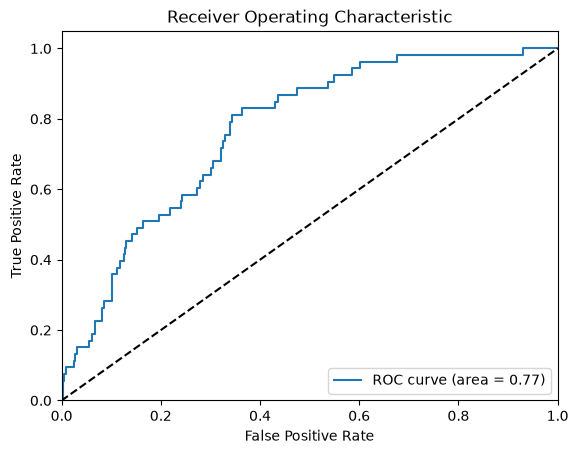

PR AUC: 0.16168543748525693


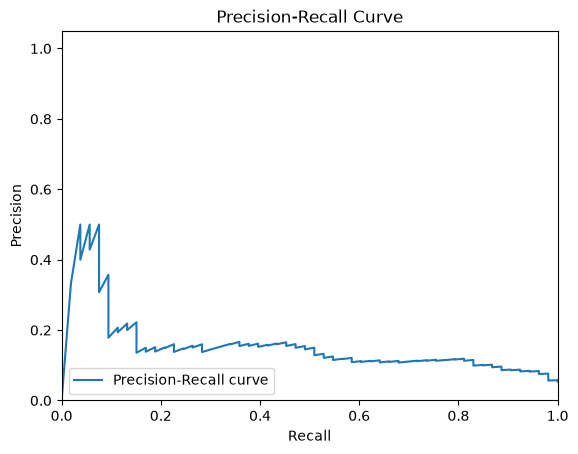

 85%|████████▍ | 11/13 [00:08<00:02,  1.04s/it]


Confusion Matrix:
 [[928   1]
 [ 53   0]]


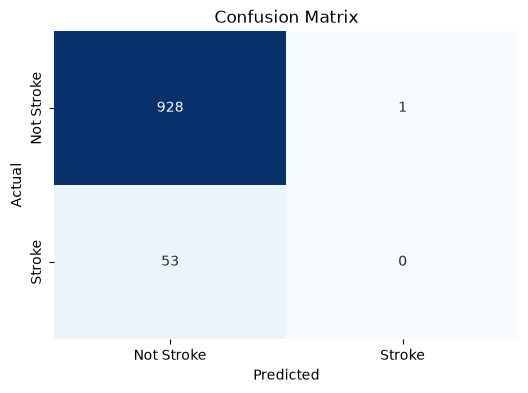


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97       929
      Stroke       0.00      0.00      0.00        53

    accuracy                           0.95       982
   macro avg       0.47      0.50      0.49       982
weighted avg       0.89      0.95      0.92       982

ROC-AUC: 0.8067104007149095


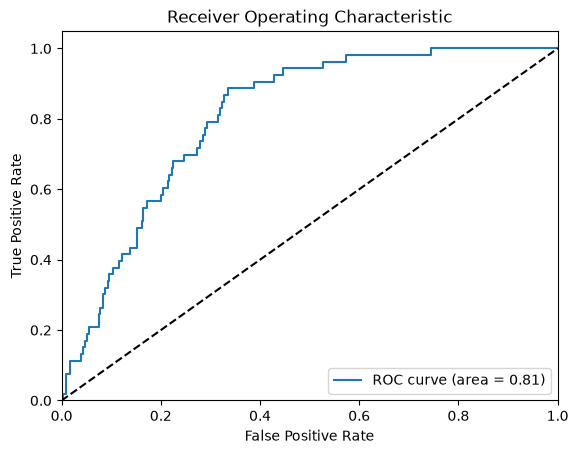

PR AUC: 0.15944507970595082


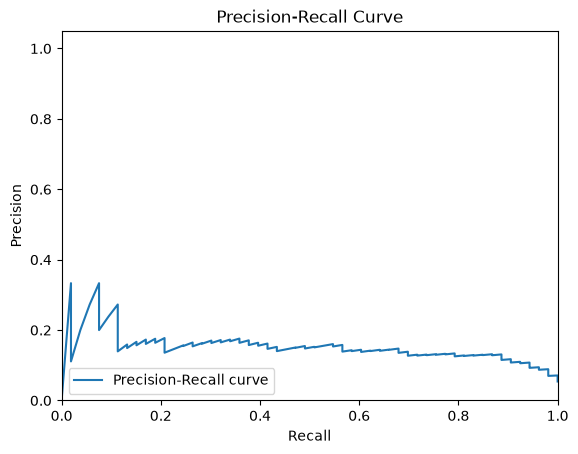

 92%|█████████▏| 12/13 [00:10<00:01,  1.51s/it]

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 156, number of negative: 3771
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000460 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 633
[LightGBM] [Info] Number of data points in the train set: 3927, number of used features: 14
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.039725 -> initscore=-3.185239
[LightGBM] [Info] Start training from score -3.185239

Confusion Matrix:
 [[924   5]
 [ 52   1]]


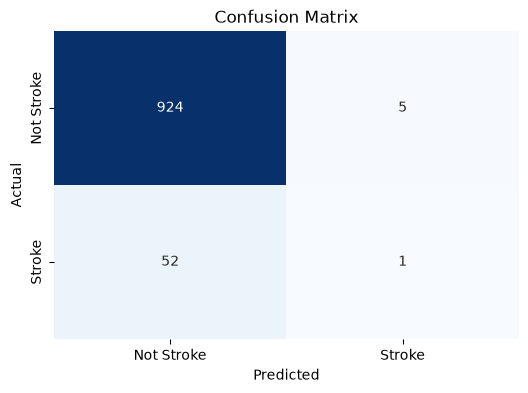


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      0.99      0.97       929
      Stroke       0.17      0.02      0.03        53

    accuracy                           0.94       982
   macro avg       0.56      0.51      0.50       982
weighted avg       0.90      0.94      0.92       982

ROC-AUC: 0.800089363689908


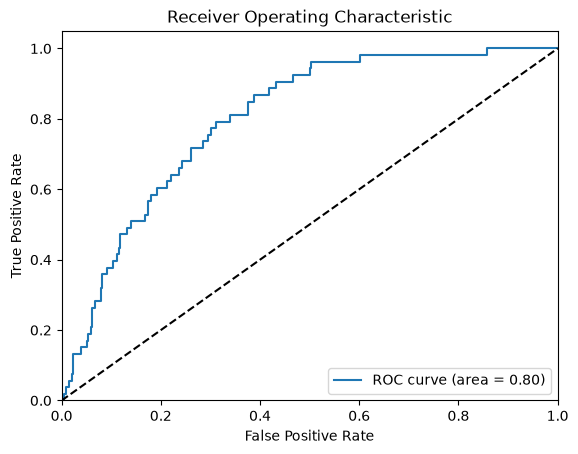

PR AUC: 0.15605394618336155


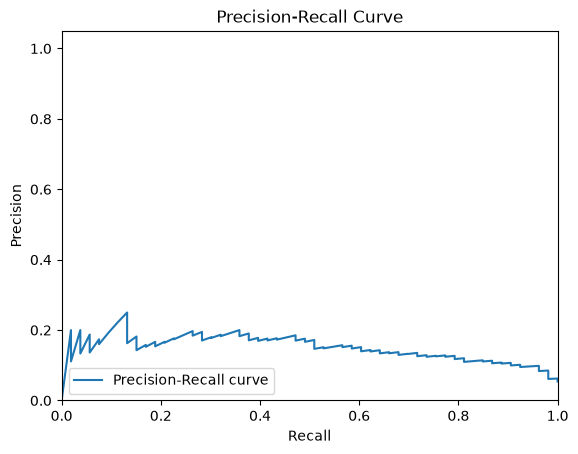

100%|██████████| 13/13 [00:11<00:00,  1.18it/s]


In [102]:
results = {}

for name, model in tqdm(models.items()):
    model.fit(x_train, y_train)

    train_pred = model.predict(x_train)
    test_pred  = model.predict(x_test)
    
    

    cm = confusion_matrix(y_test, test_pred)
    print("\nConfusion Matrix:\n", cm)

    plt.figure(figsize=(6,4))
    sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
                xticklabels=['Not Stroke','Stroke']
                ,yticklabels=['Not Stroke','Stroke'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title('Confusion Matrix')
    plt.show()

    # Full classification report
    print("\nClassification Report:\n")
    print(classification_report(y_test, test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

    y_pred_prob = model.predict_proba(x_test)[:, 1]
    roc_auc = roc_auc_score(y_test, y_pred_prob)
    print("ROC-AUC:", roc_auc)

    # ROC curve
    fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
    plt.plot([0, 1], [0, 1], 'k--') 
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

    pr_auc = average_precision_score(y_test, y_pred_prob)
    print("PR AUC:", pr_auc)

    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend(loc="lower left")
    plt.show()

    results[name] = {
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train Precision": precision_score(y_train, train_pred),
        "Test Precision": precision_score(y_test, test_pred),
        "Train Recall": recall_score(y_train, train_pred),
        "Test Recall": recall_score(y_test, test_pred),
        "Train F1 Score": f1_score(y_train, train_pred),
        "Test F1 Score": f1_score(y_test, test_pred),
        "Train Balanced Accuracy": balanced_accuracy_score(y_train, train_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, test_pred),
        "ROC-AUC": roc_auc,
        "PR AUC": pr_auc

    }
    

In [103]:
results_df = pd.DataFrame(results).T
display(results_df)

,Train Accuracy,Test Accuracy,Train Precision,Test Precision,Train Recall,Test Recall,Train F1 Score,Test F1 Score,Train Balanced Accuracy,Test Balanced Accuracy,ROC-AUC,PR AUC
Logistic Regression,0.960530,0.946029,1.000000,0.000000,0.006410,0.000000,0.012739,0.000000,0.503205,0.500000,0.853911,0.220913
KNN,0.960020,0.945010,0.454545,0.000000,0.032051,0.000000,0.059880,0.000000,0.515230,0.499462,0.625850,0.088344
SVC,0.960275,0.946029,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.500000,0.500000,0.667120,0.139483
Decision Tree,1.000000,0.923625,1.000000,0.210526,1.000000,0.150943,1.000000,0.175824,1.000000,0.559325,0.559325,0.077602
Naive Bayes,0.369748,0.381874,0.058622,0.080303,0.987179,1.000000,0.110672,0.148668,0.665693,0.673305,0.822796,0.182544
Random Forest,1.000000,0.946029,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.500000,0.802527,0.189352
Extra Trees,1.000000,0.943992,1.000000,0.333333,1.000000,0.037736,1.000000,0.067797,1.000000,0.516715,0.743425,0.147466
AdaBoost,0.960275,0.946029,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.500000,0.500000,0.811636,0.149589
Gradient Boosting,0.966896,0.943992,1.000000,0.000000,0.166667,0.000000,0.285714,0.000000,0.583333,0.498924,0.842964,0.191459
Hist Gradient Boosting,0.997708,0.945010,1.000000,0.333333,0.942308,0.018868,0.970297,0.035714,0.971154,0.508358,0.797876,0.155414
